# Optuna Hyperparameter Tuning: Food Delivery ETA Prediction
###

**Project question:** Can we predict how many minutes a food order will take to arrive, and can Optuna help us find better Random Forest settings?

You will learn:
- what hyperparameters are and why tuning matters
- how to create and inspect a realistic practice dataset
- how to compare manually chosen parameter sets fairly
- how Optuna searches for better settings
- how to visualize trials and evaluate the final model
- how to repeat experiments by changing one factor at a time

**Dataset note:** This generates synthetic delivery data. It is designed for learning, not for operational ETA decisions. Real delivery systems need real historical data, careful validation, privacy controls, and monitoring.

## 1. Run this notebook in Google Colab

1. Open [Google Colab](https://colab.research.google.com/).
2. Select **New notebook**.
3. Rename it `Optuna_Food_Delivery_ETA_Practice`.
4. Copy the cells in this manual into Colab in order, or upload the supplied `.ipynb` file.
5. Select **Runtime → Run all**. If Colab asks to install packages, allow the install cell to finish.

Use a fresh runtime if you get confusing `NameError` errors. Run cells from top to bottom.

## 2. Install the packages

In [16]:
%pip -q install optuna scikit-learn pandas numpy matplotlib

## 3. Imports and reproducibility
A random seed makes the generated data and split repeatable in this notebook. Small numerical differences can still occur across software versions.

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
np.random.seed(SEED)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("scikit-learn ready")
print("Optuna:", optuna.__version__)

NumPy: 2.1.3
Pandas: 2.2.3
scikit-learn ready
Optuna: 5.0.0


## 4. Understand the real-world scenario

A food-delivery platform may estimate delivery time using information known when an order is placed or accepted.

| Input feature | Example | Why it may matter |
|---|---:|---|
| Distance | 4.2 km | Longer trips often take longer |
| Preparation time | 16 min | Kitchen workload affects readiness |
| Traffic | High | Congestion delays travel |
| Weather | Rain | Rain can slow travel |
| Courier experience | 3.5 years | Experience may affect efficiency |
| Vehicle | Scooter | Vehicle type may affect speed |

**Target:** `delivery_time_min`, the total delivery time in minutes.

The data below are simulated from a simple rule plus random noise. The model does not get to see the rule directly; it learns patterns from examples.

## 5. Generate the practice dataset

In [18]:
rng = np.random.default_rng(SEED)
n_rows = 6000

distance_km = rng.uniform(0.5, 20.0, n_rows)
prep_time_min = np.clip(rng.normal(15, 5, n_rows), 5, 40)
traffic_level = rng.choice(["Low", "Medium", "High"], n_rows, p=[0.30, 0.45, 0.25])
weather = rng.choice(["Clear", "Rain", "Poor"], n_rows, p=[0.65, 0.25, 0.10])
courier_experience_years = rng.uniform(0, 12, n_rows)
vehicle_type = rng.choice(["Bike", "Scooter", "Car"], n_rows, p=[0.35, 0.45, 0.20])

traffic_effect = pd.Series(traffic_level).map({"Low": 0, "Medium": 7, "High": 16}).to_numpy()
weather_effect = pd.Series(weather).map({"Clear": 0, "Rain": 5, "Poor": 11}).to_numpy()
vehicle_effect = pd.Series(vehicle_type).map({"Bike": 3, "Scooter": 1, "Car": 0}).to_numpy()
noise = rng.normal(0, 4, n_rows)

delivery_time_min = (
    8
    + distance_km * 3.0
    + prep_time_min * 0.75
    + traffic_effect
    + weather_effect
    + vehicle_effect
    - courier_experience_years * 0.35
    + noise
)
delivery_time_min = np.clip(delivery_time_min, 8, None)

df = pd.DataFrame({
    "distance_km": distance_km,
    "prep_time_min": prep_time_min,
    "traffic_level": traffic_level,
    "weather": weather,
    "courier_experience_years": courier_experience_years,
    "vehicle_type": vehicle_type,
    "delivery_time_min": delivery_time_min
})

# Display the first five rows
display(df.head())

# Display dataset dimensions
print("Dataset shape:", df.shape)

# Display summary statistics for numeric columns
numeric_df = df.select_dtypes(include="number")
display(numeric_df.describe().round(2))

# Display column names and data types
print("\nColumn information:")
df.info()

,distance_km,prep_time_min,traffic_level,weather,courier_experience_years,vehicle_type,delivery_time_min
0,15.592143,9.815030,Medium,Rain,4.910582,Car,65.679453
1,9.058130,17.413177,Low,Clear,8.359564,Car,48.989973
2,17.242659,11.962355,Medium,Rain,3.792779,Scooter,77.325774
3,14.098677,6.754668,High,Rain,6.558043,Scooter,75.681485
4,2.336458,13.562644,Low,Rain,2.851765,Scooter,29.554599


Dataset shape: (6000, 7)


,distance_km,prep_time_min,courier_experience_years,delivery_time_min
count,6000.00,6000.00,6000.00,6000.00
mean,10.15,14.98,6.04,58.59
std,5.62,4.95,3.46,19.19
min,0.51,5.00,0.00,9.27
25%,5.25,11.61,3.03,43.76
50%,10.10,14.80,6.03,58.53
75%,15.07,18.33,9.05,73.48
max,20.00,35.76,12.00,113.31



Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 7 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   distance_km               6000 non-null   float64
 1   prep_time_min             6000 non-null   float64
 2   traffic_level             6000 non-null   object 
 3   weather                   6000 non-null   object 
 4   courier_experience_years  6000 non-null   float64
 5   vehicle_type              6000 non-null   object 
 6   delivery_time_min         6000 non-null   float64
dtypes: float64(4), object(3)
memory usage: 328.3+ KB


## 6. Explore the data with visualizations

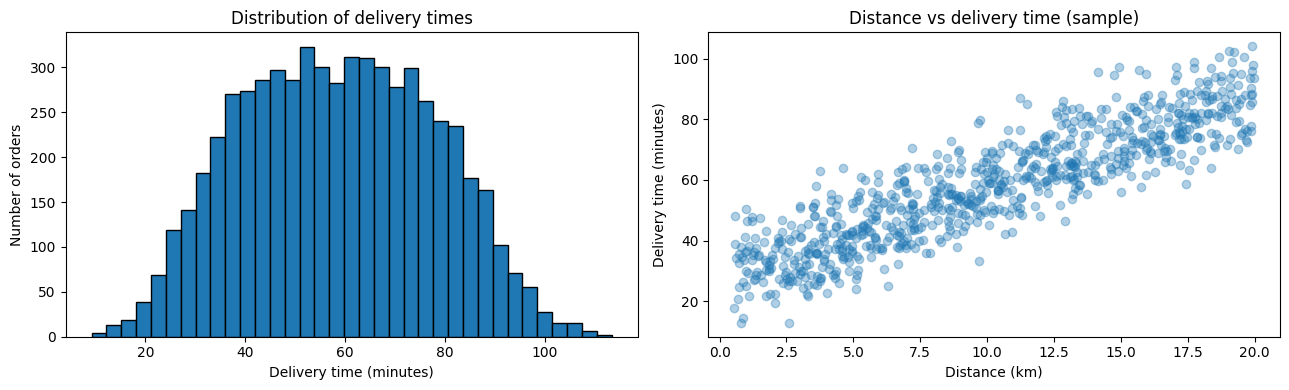

,mean,median,count
traffic_level,,,
High,67.69,67.45,1528
Low,51.29,51.13,1788
Medium,58.28,58.16,2684


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(df["delivery_time_min"], bins=35, edgecolor="black")
axes[0].set_title("Distribution of delivery times")
axes[0].set_xlabel("Delivery time (minutes)")
axes[0].set_ylabel("Number of orders")

sample = df.sample(800, random_state=SEED)
axes[1].scatter(sample["distance_km"], sample["delivery_time_min"], alpha=0.35)
axes[1].set_title("Distance vs delivery time (sample)")
axes[1].set_xlabel("Distance (km)")
axes[1].set_ylabel("Delivery time (minutes)")

plt.tight_layout()
plt.show()

display(df.groupby("traffic_level")["delivery_time_min"].agg(["mean", "median", "count"]).round(2))

## 7. Split the data and build a safe preprocessing pipeline

We keep a test set aside until the end. We use cross-validation only on the training data to compare hyperparameters.

The categorical columns are converted to numeric indicator columns with `OneHotEncoder`. The preprocessing is inside the pipeline so each cross-validation fold learns its preprocessing from its own training fold. This helps avoid data leakage.

In [20]:
target = "delivery_time_min"
X = df.drop(columns=[target])
y = df[target]

numeric_features = [
    "distance_km", "prep_time_min", "courier_experience_years"
]
categorical_features = ["traffic_level", "weather", "vehicle_type"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)

def make_model(params=None):
    params = params or {}
    preprocessor = ColumnTransformer(
        transformers=[
            ("numeric", "passthrough", numeric_features),
            ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ]
    )
    model = RandomForestRegressor(
        random_state=SEED,
        n_jobs=1,
        **params
    )
    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 4800
Test rows: 1200


## 8. Hyperparameters in plain language

A **parameter** is learned from data during training, such as a split point in a decision tree. A **hyperparameter** is a setting chosen before training.

| Hyperparameter | Plain-language meaning | Typical trade-off |
|---|---|---|
| `n_estimators` | Number of trees in the forest | More trees can stabilize predictions but take longer |
| `max_depth` | Maximum depth of each tree | Deep trees can learn complex patterns but may overfit |
| `min_samples_split` | Minimum rows needed to split a node | Larger values make trees less eager to split |
| `min_samples_leaf` | Minimum rows allowed in a leaf | Larger leaves usually smooth predictions |
| `max_features` | How many input features each split can consider | Smaller values add randomness and may generalize better or worse |

**MAE (Mean Absolute Error)** is our main metric. If MAE is 4.2, predictions are off by about 4.2 minutes on average, in absolute terms. For this exercise, **lower MAE is better**.

## 9. Establish a baseline model

In [21]:
baseline_params = {
    "n_estimators": 100,
    "max_depth": None,
    "min_samples_split": 2,
    "min_samples_leaf": 1,
    "max_features": 1.0
}

baseline_model = make_model(baseline_params)
baseline_cv_mae = -cross_val_score(
    baseline_model, X_train, y_train,
    cv=cv, scoring="neg_mean_absolute_error", n_jobs=1
)
print(f"Baseline 5-fold CV MAE: {baseline_cv_mae.mean():.3f} ± {baseline_cv_mae.std():.3f} minutes")

Baseline 5-fold CV MAE: 3.684 ± 0.059 minutes


## 10. Compare manually selected hyperparameter sets

These configurations are deliberately different. The point is to observe how model complexity and randomness affect validation error. Do not assume the most complicated model must win.

We use the **same cross-validation folds** for each configuration so the comparison is fair.

In [22]:
manual_configs = {
    "A - Baseline": {
        "n_estimators": 100, "max_depth": None,
        "min_samples_split": 2, "min_samples_leaf": 1, "max_features": 1.0
    },
    "B - Shallow trees": {
        "n_estimators": 100, "max_depth": 5,
        "min_samples_split": 2, "min_samples_leaf": 4, "max_features": "sqrt"
    },
    "C - More trees": {
        "n_estimators": 300, "max_depth": None,
        "min_samples_split": 2, "min_samples_leaf": 1, "max_features": 1.0
    },
    "D - Regularized": {
        "n_estimators": 200, "max_depth": 12,
        "min_samples_split": 10, "min_samples_leaf": 4, "max_features": 1.0
    },
    "E - Feature randomness": {
        "n_estimators": 200, "max_depth": 16,
        "min_samples_split": 5, "min_samples_leaf": 2, "max_features": "sqrt"
    },
}

manual_rows = []
for name, params in manual_configs.items():
    model = make_model(params)
    scores = -cross_val_score(
        model, X_train, y_train,
        cv=cv, scoring="neg_mean_absolute_error", n_jobs=1
    )
    manual_rows.append({
        "configuration": name,
        "cv_mae_mean": scores.mean(),
        "cv_mae_std": scores.std(),
        "params": str(params)
    })

manual_results = pd.DataFrame(manual_rows).sort_values("cv_mae_mean").reset_index(drop=True)
display(manual_results.round(3))

,configuration,cv_mae_mean,cv_mae_std,params
0,D - Regularized,3.660,0.046,"{'n_estimators': 200, 'max_depth': 12, 'min_sa..."
1,C - More trees,3.667,0.058,"{'n_estimators': 300, 'max_depth': None, 'min_..."
2,A - Baseline,3.684,0.059,"{'n_estimators': 100, 'max_depth': None, 'min_..."
3,E - Feature randomness,3.797,0.052,"{'n_estimators': 200, 'max_depth': 16, 'min_sa..."
4,B - Shallow trees,6.545,0.267,"{'n_estimators': 100, 'max_depth': 5, 'min_sam..."


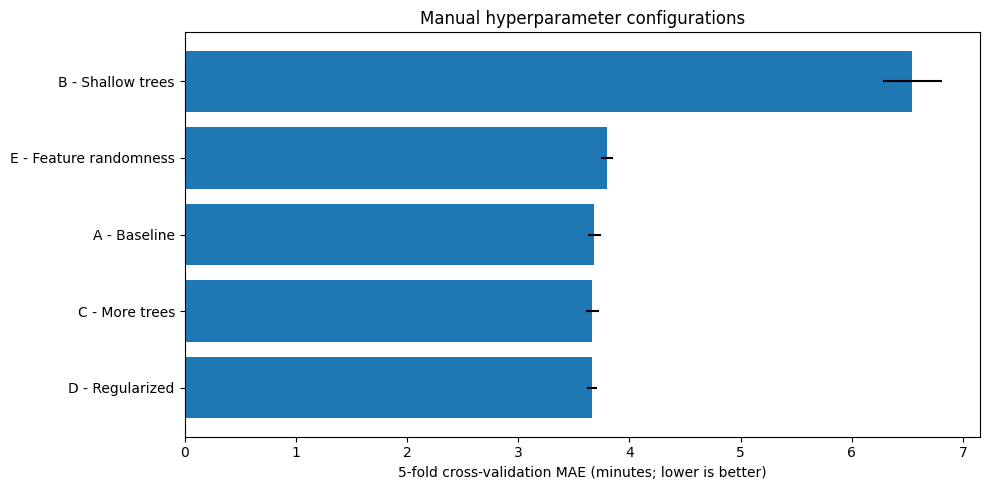

In [23]:
plot_data = manual_results.sort_values("cv_mae_mean", ascending=True)
plt.figure(figsize=(10, 5))
plt.barh(plot_data["configuration"], plot_data["cv_mae_mean"], xerr=plot_data["cv_mae_std"])
plt.xlabel("5-fold cross-validation MAE (minutes; lower is better)")
plt.title("Manual hyperparameter configurations")
plt.tight_layout()
plt.show()

**How to read the chart:** A shorter bar means lower average validation error. The error bars show the standard deviation across folds; larger variation suggests performance may be less consistent across folds.

A small difference does not automatically mean one model is truly superior. Consider validation variation, runtime, and simplicity.

## 11. Let Optuna search automatically

Optuna runs an **objective function** repeatedly:
1. It proposes a set of hyperparameters.
2. We build a model with those settings.
3. We evaluate it using the same 5-fold CV procedure.
4. We return the mean CV MAE.
5. Optuna uses past results to propose future trials.

The study uses `direction="minimize"` because smaller MAE is better. The TPE sampler learns which ranges of settings appear promising. Twenty trials are a beginner-friendly starting point; more trials usually take more time.

In [24]:
def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 400, step=100),
        "max_depth": trial.suggest_categorical("max_depth", [5, 8, 12, 16, 20, None]),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 20),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 8),
        "max_features": trial.suggest_categorical("max_features", [1.0, "sqrt", 0.7]),
    }
    model = make_model(params)
    scores = -cross_val_score(
        model, X_train, y_train,
        cv=cv, scoring="neg_mean_absolute_error", n_jobs=1
    )
    return float(scores.mean())

study = optuna.create_study(
    study_name="food_delivery_eta_tuning",
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=SEED)
)
study.optimize(objective, n_trials=20, show_progress_bar=True)

print("Completed trials:", len(study.trials))
print(f"Best CV MAE: {study.best_value:.3f} minutes")
print("Best hyperparameters:")
for key, value in study.best_params.items():
    print(f"  {key}: {value}")

[I 2026-10-25 15:17:20,709] A new study created in memory with name: food_delivery_eta_tuning


  0%|          | 0/20 [00:00<?, ?it/s]

[I 2026-10-25 15:17:28,354] Trial 0 finished with value: 4.68938519544483 and parameters: {'n_estimators': 200, 'max_depth': 5, 'min_samples_split': 18, 'min_samples_leaf': 5, 'max_features': 0.7}. Best is trial 0 with value: 4.68938519544483.
[I 2026-10-25 15:17:51,914] Trial 1 finished with value: 3.631755591738141 and parameters: {'n_estimators': 400, 'max_depth': 20, 'min_samples_split': 7, 'min_samples_leaf': 5, 'max_features': 0.7}. Best is trial 1 with value: 3.631755591738141.
[I 2026-10-25 15:17:56,552] Trial 2 finished with value: 6.404942254220865 and parameters: {'n_estimators': 200, 'max_depth': 5, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'sqrt'}. Best is trial 1 with value: 3.631755591738141.
[I 2026-10-25 15:18:10,159] Trial 3 finished with value: 3.8037356653021397 and parameters: {'n_estimators': 200, 'max_depth': 8, 'min_samples_split': 19, 'min_samples_leaf': 3, 'max_features': 1.0}. Best is trial 1 with value: 3.631755591738141.
[I 2026-10-25 1

## 12. Inspect and compare Optuna's trials

In [25]:
trials_df = study.trials_dataframe(attrs=("number", "value", "params", "state"))
display(trials_df.sort_values("value").head(10).round(3))

,number,value,params_max_depth,params_max_features,params_min_samples_leaf,params_min_samples_split,params_n_estimators,state
16,16,3.589,16.0,0.7,2,9,300,COMPLETE
17,17,3.594,NaN,0.7,2,7,300,COMPLETE
19,19,3.595,12.0,0.7,1,10,300,COMPLETE
12,12,3.602,NaN,0.7,2,12,400,COMPLETE
18,18,3.604,NaN,0.7,3,3,300,COMPLETE
10,10,3.618,20.0,0.7,4,7,400,COMPLETE
11,11,3.620,20.0,0.7,4,9,400,COMPLETE
15,15,3.621,NaN,0.7,2,15,300,COMPLETE
1,1,3.632,20.0,0.7,5,7,400,COMPLETE
13,13,3.635,NaN,0.7,4,14,400,COMPLETE


## 13. Visualization 1 — optimization history

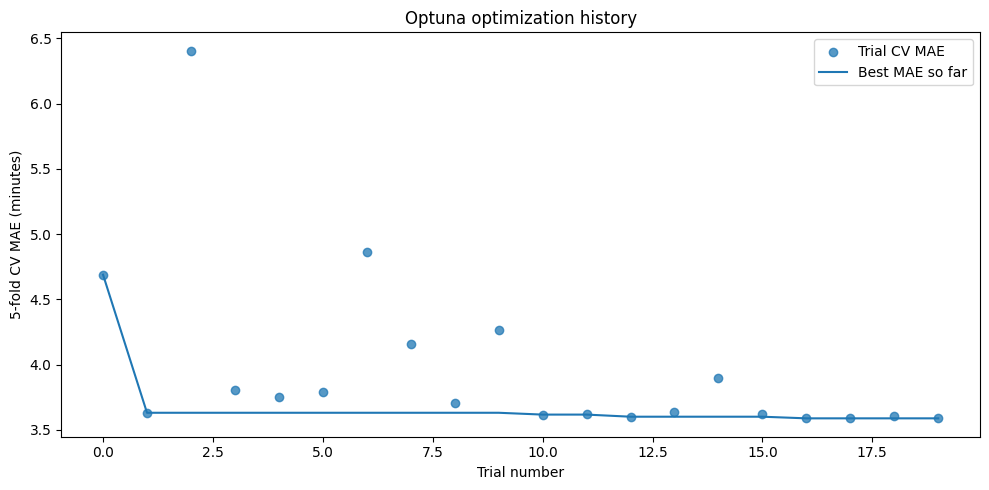

In [26]:
completed = study.trials_dataframe(attrs=("number", "value"))
completed = completed.dropna(subset=["value"]).sort_values("number")
completed["best_so_far"] = completed["value"].cummin()

plt.figure(figsize=(10, 5))
plt.scatter(completed["number"], completed["value"], alpha=0.75, label="Trial CV MAE")
plt.plot(completed["number"], completed["best_so_far"], label="Best MAE so far")
plt.xlabel("Trial number")
plt.ylabel("5-fold CV MAE (minutes)")
plt.title("Optuna optimization history")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretation:** The dots are individual trials; the line is the best score found up to each trial. It may improve quickly, then flatten. A flat line does not prove the global optimum was found—it only means these trials did not improve the best result.

## 14. Visualization 2 — parameter importance

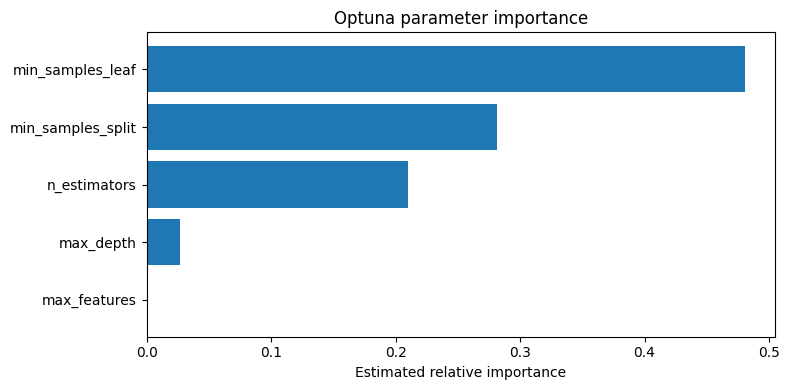

,parameter,importance
0,min_samples_leaf,0.481
1,min_samples_split,0.282
2,n_estimators,0.210
3,max_depth,0.027
4,max_features,0.001


In [27]:
try:
    importance = optuna.importance.get_param_importances(study)
    importance_df = pd.DataFrame({
        "parameter": list(importance.keys()),
        "importance": list(importance.values())
    }).sort_values("importance")

    plt.figure(figsize=(8, 4))
    plt.barh(importance_df["parameter"], importance_df["importance"])
    plt.xlabel("Estimated relative importance")
    plt.title("Optuna parameter importance")
    plt.tight_layout()
    plt.show()
    display(importance_df.sort_values("importance", ascending=False).round(3))
except Exception as exc:
    print("Parameter importance could not be calculated for this study.")
    print("Try increasing the number of trials. Details:", exc)

Parameter importance is an estimate based on this study's search space and observed trials. It is not a universal ranking of what matters for every dataset.

## 15. Visualization 3 — how scores vary with selected settings

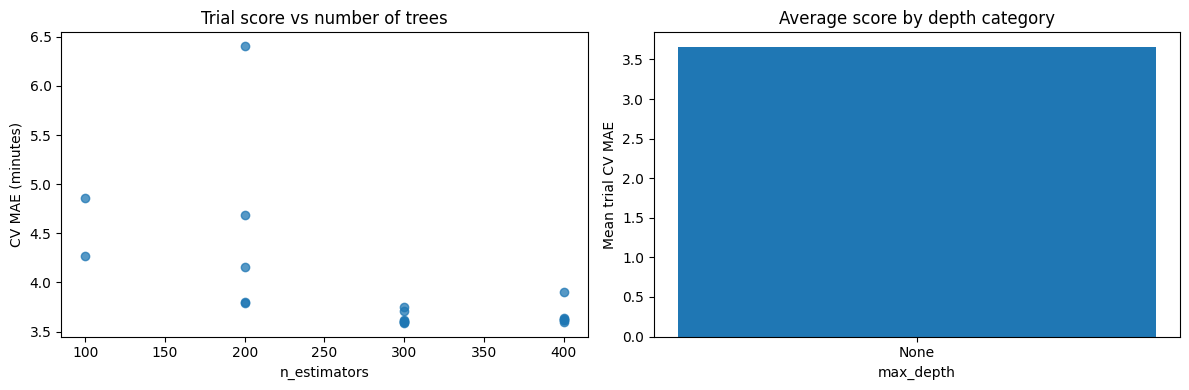

In [28]:
trial_rows = []
for t in study.trials:
    if t.value is not None:
        row = {"trial": t.number, "cv_mae": t.value}
        row.update(t.params)
        trial_rows.append(row)
trial_plot_df = pd.DataFrame(trial_rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
if not trial_plot_df.empty:
    axes[0].scatter(trial_plot_df["n_estimators"], trial_plot_df["cv_mae"], alpha=0.75)
    axes[0].set_xlabel("n_estimators")
    axes[0].set_ylabel("CV MAE (minutes)")
    axes[0].set_title("Trial score vs number of trees")

    depth_labels = trial_plot_df["max_depth"].map(lambda x: "None" if pd.isna(x) else str(x))
    depth_order = ["5", "8", "12", "16", "20", "None"]
    grouped = trial_plot_df.assign(depth_label=depth_labels).groupby("depth_label")["cv_mae"].mean()
    grouped = grouped.reindex([d for d in depth_order if d in grouped.index])
    axes[1].bar(grouped.index, grouped.values)
    axes[1].set_xlabel("max_depth")
    axes[1].set_ylabel("Mean trial CV MAE")
    axes[1].set_title("Average score by depth category")
plt.tight_layout()
plt.show()

## 16. Final evaluation — use the test set once

The test set was not used to select hyperparameters. Now compare a baseline model and the best Optuna model on that held-out test set.

This is the final check; do not repeatedly tune against test results, because that would turn the test set into another validation set.

In [29]:
best_model = make_model(study.best_params)
best_model.fit(X_train, y_train)

baseline_final = make_model(baseline_params)
baseline_final.fit(X_train, y_train)

def evaluate_model(name, model):
    predictions = model.predict(X_test)
    return {
        "model": name,
        "MAE_minutes": mean_absolute_error(y_test, predictions),
        "RMSE_minutes": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    }

final_results = pd.DataFrame([
    evaluate_model("Baseline Random Forest", baseline_final),
    evaluate_model("Optuna-tuned Random Forest", best_model)
])
display(final_results.round(3))

,model,MAE_minutes,RMSE_minutes,R2
0,Baseline Random Forest,3.690,4.621,0.944
1,Optuna-tuned Random Forest,3.569,4.485,0.947


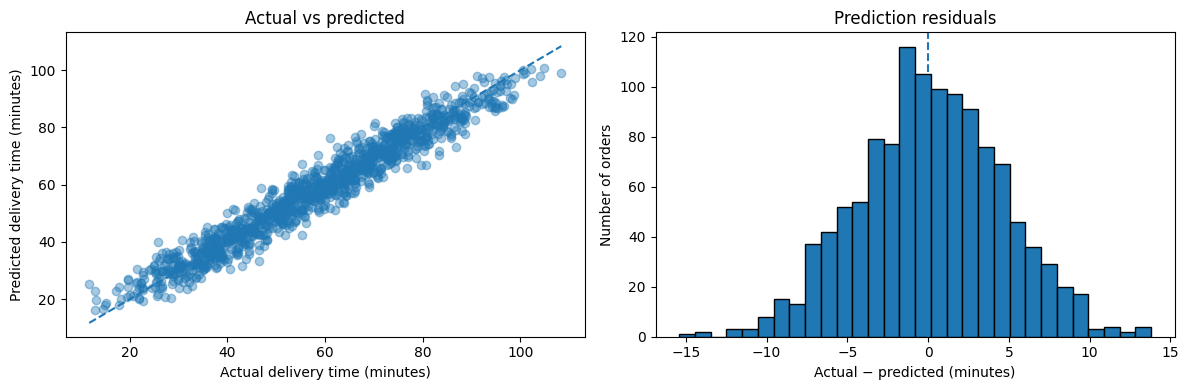

In [30]:
best_predictions = best_model.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(y_test, best_predictions, alpha=0.4)
low = min(float(y_test.min()), float(best_predictions.min()))
high = max(float(y_test.max()), float(best_predictions.max()))
axes[0].plot([low, high], [low, high], linestyle="--")
axes[0].set_xlabel("Actual delivery time (minutes)")
axes[0].set_ylabel("Predicted delivery time (minutes)")
axes[0].set_title("Actual vs predicted")

residuals = y_test.to_numpy() - best_predictions
axes[1].hist(residuals, bins=30, edgecolor="black")
axes[1].axvline(0, linestyle="--")
axes[1].set_xlabel("Actual − predicted (minutes)")
axes[1].set_ylabel("Number of orders")
axes[1].set_title("Prediction residuals")

plt.tight_layout()
plt.show()

**Metrics reminder**
- **MAE:** average absolute error in minutes; easy to explain.
- **RMSE:** penalizes larger errors more strongly than MAE.
- **R²:** compares the model with a simple mean-target reference; closer to 1 is generally better, but it is not an error measured in minutes.

Optuna is not guaranteed to beat the baseline on every run or dataset. The purpose is a disciplined, reproducible search—not a promise of improvement.

## 17. Repeat the experiment - exercises

Run one exercise at a time. Keep the data split and CV folds unchanged when you want a fair comparison. Use a new study name for each experiment.

### Exercise A — compare trial budgets
Change `n_trials=20` to `10`, then `30`, then `50`. Record best CV MAE and runtime. More trials give Optuna more opportunities but take longer.

### Exercise B — focus on shallow trees
Inside `objective`, replace the `max_depth` line with:
```python
"max_depth": trial.suggest_categorical("max_depth", [3, 5, 8]),
```
Run a new study named `food_eta_shallow_trees`.

### Exercise C — test smoother leaves
Change `min_samples_leaf` to:
```python
"min_samples_leaf": trial.suggest_int("min_samples_leaf", 4, 15),
```
Does restricting leaf size improve or worsen validation MAE?

### Exercise D — prioritize more trees
Change `n_estimators` to:
```python
"n_estimators": trial.suggest_int("n_estimators", 100, 800, step=100),
```
Compare quality against runtime.

### Exercise E — optimize RMSE instead of MAE
Inside the objective, use `scoring="neg_root_mean_squared_error"` and continue returning `float(-scores.mean())`. Compare which settings are chosen and how MAE/RMSE change.

### Exercise F — make the scenario noisier
Change `noise = rng.normal(0, 4, n_rows)` to `noise = rng.normal(0, 8, n_rows)`, regenerate the dataset, and rerun all later cells. You should usually expect prediction to become harder, but exact results depend on the split and settings.

**Record your results:** experiment name, search space, number of trials, best CV MAE, test MAE, test RMSE, runtime, and what you learned.

## 18. Common problems and fixes

| Problem | Fix |
|---|---|
| `ModuleNotFoundError: No module named 'optuna'` | Run the install cell, wait for it to finish, then rerun imports. |
| `NameError` for `df`, `study`, or a model | Select **Runtime → Run all**; cells may have been run out of order. |
| Notebook runs slowly | Start with 5–10 trials or temporarily use 3 CV folds for experimentation; use 5 folds for the main comparison. |
| Best score does not improve | This is possible. Try more trials or a different search space, and compare against the same CV folds. |
| Parameter-importance plot fails | Ensure multiple completed trials exist; increase the trial count if necessary. |
| Different result after changing code | Confirm the seed, data-generation cell, split, and CV settings are unchanged. |
| `max_depth=None` appears blank in the table | Pandas may display `None` as a missing value; this is expected for a categorical setting. |

## 19. How this fits into a real MLOps workflow

A production-style workflow often looks like:

1. **Data versioning:** track training data or data references using DVC and object storage such as S3.
2. **Experiment tracking:** log parameters, metrics, artifacts, and code version with MLflow.
3. **Hyperparameter tuning:** run Optuna locally, in a notebook, or on managed/cloud compute.
4. **Reproducibility:** store the best parameters, random seed, data version, package versions, and evaluation report.
5. **Model approval:** compare performance to a baseline and business thresholds before release.
6. **Deployment:** expose the approved model via a service or batch job.
7. **Monitoring:** track prediction errors when labels become available, data drift, latency, and service health.

For a real ETA product, also evaluate peak-hour performance, geographic fairness, traffic/weather shifts, and the cost of being late versus early. Do not deploy a synthetic-data model.

## 20. Quick knowledge check

1. What is the difference between a model parameter and a hyperparameter?
2. Why do we use cross-validation for manual configurations and Optuna trials?
3. Why is the test set held back until the end?
4. If MAE is 5.0 minutes, what does that mean in everyday language?
5. Why might a very deep tree overfit?
6. Why is Optuna not guaranteed to find the global best configuration?
7. What is the difference between MAE and RMSE?
8. What information should you save to reproduce a tuning run?

### Suggested answers
1. Parameters are learned during fitting; hyperparameters are chosen before fitting.
2. To compare settings over multiple folds rather than relying on one lucky split.
3. To get a fair final estimate after tuning choices are complete.
4. Predictions are about five minutes away from actual values on average, measured in absolute terms.
5. It can learn noise and small details that do not generalize.
6. It explores a finite number of trials in a defined search space.
7. RMSE penalizes large errors more; both are in target units here.
8. Data version, code, package versions, seed, CV strategy, search space, trials, best parameters, and metrics.

## 21. Useful official references
- [Optuna documentation](https://optuna.readthedocs.io/en/stable/)
- [Optuna tutorials](https://optuna.readthedocs.io/en/stable/tutorial/)
- [scikit-learn cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html)
- [RandomForestRegressor API](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html)
- [Google Colab FAQ](https://research.google.com/colaboratory/faq.html)

